# **My Final Project - Human Development Analysis**

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
df = pd.read_csv("Human Development Index - Full.csv")

# **Data Manipulation**
I actually did data manipulation because the original dataset has over 800 columns and was impossible to read. It had every type of human development variable per year per column, and it was difficult to analyze.

In [54]:
# -----------------------------------------
# CREATE A CLEAN LONG-FORM DATAFRAME
# -----------------------------------------

# 1. Columns that should remain unchanged
id_cols = [
    'ISO3',
    'Country',
    'Human Development Groups',
    'UNDP Developing Regions',
    'HDI Rank (2021)'
]

# 2. Every column after those 5 is a year-based variable
year_cols = df.columns[5:].tolist()

# 3. Melt the year-based columns
#    This preserves every value while putting the year-based
#    column names into one column.
long_df = df[id_cols + year_cols].melt(
    id_vars=id_cols,
    var_name='Indicator_Year',
    value_name='Value'
)

# 4. Separate the indicator name from the year
#    Example:
#    "Human Development Index (1990)"
#    becomes:
#    Indicator = "Human Development Index"
#    Year = 1990
long_df[['Indicator', 'Year']] = long_df['Indicator_Year'].str.extract(
    r'^(.*?) \((\d{4})\)$'
)

# 5. Convert Year from text to an integer
long_df['Year'] = long_df['Year'].astype(int)

# 6. We no longer need the original combined column
long_df = long_df.drop(columns='Indicator_Year')

# 7. Put the columns in the order we want
long_df = long_df[
    id_cols + ['Indicator', 'Year', 'Value']
]

In [55]:
long_df
#awesome! This make it so the data was flipped on its head and is a long dataset
#where the years are one column combined instead of spread out through each variable.

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Indicator,Year,Value
0,AFG,Afghanistan,Low,SA,180.0,Human Development Index,1990,0.273
1,AGO,Angola,Medium,SSA,148.0,Human Development Index,1990,NaN
2,ALB,Albania,High,ECA,67.0,Human Development Index,1990,0.647
3,AND,Andorra,Very High,NaN,40.0,Human Development Index,1990,NaN
4,ARE,United Arab Emirates,Very High,AS,26.0,Human Development Index,1990,0.728
...,...,...,...,...,...,...,...,...
170620,WSM,Samoa,High,EAP,111.0,Material footprint per capita (tonnes),2021,NaN
170621,YEM,Yemen,Low,AS,183.0,Material footprint per capita (tonnes),2021,2.890
170622,ZAF,South Africa,High,SSA,109.0,Material footprint per capita (tonnes),2021,7.550
170623,ZMB,Zambia,Medium,SSA,154.0,Material footprint per capita (tonnes),2021,2.380


In [56]:
#long-format data and reshapes it again so that each indicator becomes its own column. New dataframe is named hd for human development
hd = long_df.pivot_table(
    index=['ISO3', 'Country', 'Human Development Groups',
           'UNDP Developing Regions', 'HDI Rank (2021)', 'Year'],
    columns='Indicator',
    values='Value',
    aggfunc='first'
).reset_index()

#Remove the column index label
hd.columns.name = None

In [57]:
hd.head()
#great. This is what I want my dataset to look like to work with and clean.
#I want every human developmenbt variable to be a column, but keep years in one whole column. This makes for easy analysis and reading.

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,...,Life Expectancy at Birth,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index
0,AFG,Afghanistan,Low,SA,180.0,1990,142.960,0.209727,NaN,NaN,...,45.9672,48.3973,43.7088,2.33,1500.0,0.971125,0.342503,1.311020,NaN,0.270
1,AFG,Afghanistan,Low,SA,180.0,1991,147.525,0.182525,NaN,NaN,...,46.6631,49.1439,44.3528,2.28,1530.0,1.019356,0.371860,1.385486,NaN,0.276
2,AFG,Afghanistan,Low,SA,180.0,1992,147.521,0.095233,NaN,NaN,...,47.5955,50.3197,45.0697,2.35,1520.0,1.067586,0.401218,1.459952,NaN,0.284
3,AFG,Afghanistan,Low,SA,180.0,1993,147.896,0.084285,NaN,NaN,...,51.4664,52.7389,50.2164,2.10,1480.0,1.115817,0.430575,1.534418,NaN,0.294
4,AFG,Afghanistan,Low,SA,180.0,1994,155.669,0.075054,NaN,NaN,...,51.4945,53.5442,49.5307,1.83,1540.0,1.164047,0.459933,1.608884,NaN,0.289


# **Cleaning the Data**
Now that I have my dataset looking the way I want it, I can clean that data.

In [58]:
#Check for duplicate country-year combinations
hd.duplicated(
    subset=['ISO3', 'Country', 'Year']
).sum()
#there are no duplicates!!

np.int64(0)

In [59]:
#checking for missing values
hd.isnull().sum()
#there are missing values. I am not going to do anything with that data until I approach the data.
#If It doesn't apply then I won't worry about it. I dont want to remove rows or columns just because of null data

,0
ISO3,0
Country,0
Human Development Groups,0
UNDP Developing Regions,0
HDI Rank (2021),0
Year,0
"Adolescent Birth Rate (births per 1,000 women ages 15-19)",0
Carbon dioxide emissions per capita (production) (tonnes),23
Coefficient of human inequality,3461
Difference from HDI rank,4620


In [60]:
#checking for outliers
hd.describe()

,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,Difference from HDI value (%),Expected Years of Schooling,"Expected Years of Schooling, female","Expected Years of Schooling, male",...,Life Expectancy at Birth,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index
count,4736.000000,4736.000000,4736.000000,4713.000000,1275.000000,116.000000,3448.000000,4552.000000,4217.000000,4217.000000,...,4736.000000,4736.000000,4736.000000,3673.000000,4576.000000,4323.000000,4042.000000,4042.000000,1275.000000,3448.000000
mean,116.527027,2005.500000,72.692858,3.352609,23.204339,3.250000,7.512266,10.980206,10.913642,11.124324,...,65.801481,68.329517,63.397777,10.332763,292.084572,6.659818,6.152077,7.105580,23.699062,0.548718
std,44.160475,9.234068,44.671869,6.323651,8.721626,26.893308,10.116654,2.992440,3.517315,2.666348,...,8.927743,9.419681,8.597226,12.616656,366.705261,2.880560,3.204546,2.661353,8.888138,0.117663
min,12.000000,1990.000000,2.275000,0.015895,5.255721,-109.000000,0.222222,2.059570,1.149177,2.633210,...,14.098500,15.663000,13.071400,0.010000,2.000000,0.290000,0.100000,0.500000,5.321782,0.210000
25%,80.000000,1997.750000,37.304250,0.383556,16.236522,1.000000,1.952913,9.153190,8.708618,9.636010,...,60.242750,62.058800,58.335175,3.320000,46.000000,4.378113,3.458196,5.139589,16.711822,0.464000
50%,117.500000,2005.500000,65.820000,1.235591,22.864382,6.000000,4.390981,11.433159,11.411790,11.519620,...,67.795650,70.538950,65.034700,6.260000,119.000000,6.652000,6.094560,7.018211,23.539519,0.565000
75%,154.250000,2013.250000,99.989500,3.473292,29.882879,18.000000,8.429862,13.003071,13.464577,12.883790,...,72.608875,75.782150,69.696925,11.750000,445.250000,8.883375,8.803581,9.017951,30.803535,0.642000
max,191.000000,2021.000000,214.486000,68.723812,44.834668,46.000000,74.545455,18.869200,19.360460,18.819380,...,83.758400,85.908600,81.581200,107.420000,2990.000000,12.883010,12.896940,12.847670,45.778612,0.778000


In [61]:
#counting for duplicate rows
#awesome, there are none
hd.duplicated().value_counts()

,count
False,4736


In [105]:
#fixing a column
hd['Inequality in education'] = hd['Inequality in eduation']

In [106]:
hd.head()
#this looks pretty good!
# a lot of the null values are coefficients of human inequality which are already
#statistical pulls of the original data.

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,...,"Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index,Inequality in education,Region
0,AFG,Afghanistan,Low,SA,180.0,1990,142.960,0.209727,NaN,NaN,...,43.7088,2.33,1500.0,0.971125,0.342503,1.311020,NaN,0.270,NaN,South Asia
1,AFG,Afghanistan,Low,SA,180.0,1991,147.525,0.182525,NaN,NaN,...,44.3528,2.28,1530.0,1.019356,0.371860,1.385486,NaN,0.276,NaN,South Asia
2,AFG,Afghanistan,Low,SA,180.0,1992,147.521,0.095233,NaN,NaN,...,45.0697,2.35,1520.0,1.067586,0.401218,1.459952,NaN,0.284,NaN,South Asia
3,AFG,Afghanistan,Low,SA,180.0,1993,147.896,0.084285,NaN,NaN,...,50.2164,2.10,1480.0,1.115817,0.430575,1.534418,NaN,0.294,NaN,South Asia
4,AFG,Afghanistan,Low,SA,180.0,1994,155.669,0.075054,NaN,NaN,...,49.5307,1.83,1540.0,1.164047,0.459933,1.608884,NaN,0.289,NaN,South Asia


In [65]:
hd.columns

Index(['ISO3', 'Country', 'Human Development Groups',
       'UNDP Developing Regions', 'HDI Rank (2021)', 'Year',
       'Adolescent Birth Rate (births per 1,000 women ages 15-19)',
       'Carbon dioxide emissions per capita (production) (tonnes)',
       'Coefficient of human inequality', 'Difference from HDI rank',
       'Difference from HDI value (%)', 'Expected Years of Schooling',
       'Expected Years of Schooling, female',
       'Expected Years of Schooling, male', 'GDI Group', 'GII Rank',
       'Gender Development Index', 'Gender Inequality Index',
       'Gross National Income Per Capita',
       'Gross National Income Per Capita, female',
       'Gross National Income Per Capita, male', 'HDI female', 'HDI male',
       'Human Development Index', 'Inequality in eduation',
       'Inequality in income', 'Inequality in life expectancy',
       'Inequality-adjusted Human Development Index',
       'Labour force participation rate, female (% ages 15 and older)',
       'Labo

In [66]:
hd['Coefficient of human inequality'].isna().sum()
# there are majority null values in this column, but I also don't need to remove that column as of right now.

np.int64(3461)

In [67]:
hd['Year'].value_counts()
#just wanted to double check
# the hd data set covers years from 1990 to 2021

,count
Year,
1990,148
1991,148
1992,148
1993,148
1994,148
1995,148
1996,148
1997,148
1998,148


In [107]:
hd['Country'].unique()
#I will be copying this down to sort each company into their own region.

array(['Afghanistan', 'Angola', 'Albania', 'United Arab Emirates',
       'Argentina', 'Armenia', 'Antigua and Barbuda', 'Azerbaijan',
       'Burundi', 'Benin', 'Burkina Faso', 'Bangladesh', 'Bahrain',
       'Bahamas', 'Bosnia and Herzegovina', 'Belarus', 'Belize',
       'Bolivia', 'Brazil', 'Barbados', 'Brunei', 'Bhutan', 'Botswana',
       'Central African Republic', 'Chile', 'China', 'Ivory Coast',
       'Cameroon', 'The Democratic Republic of the Congo', 'Congo',
       'Colombia', 'Comoros', 'Cabo Verde', 'Costa Rica', 'Cuba',
       'Djibouti', 'Dominica', 'Dominican Republic', 'Algeria', 'Ecuador',
       'Egypt', 'Eritrea', 'Ethiopia', 'Fiji', 'Micronesia', 'Gabon',
       'Georgia', 'Ghana', 'Guinea', 'Gambia', 'Guinea-Bissau',
       'Equatorial Guinea', 'Grenada', 'Guatemala', 'Guyana', 'Honduras',
       'Haiti', 'Indonesia', 'India', 'Iran', 'Iraq', 'Jamaica', 'Jordan',
       'Kazakhstan', 'Kenya', 'Kyrgyzstan', 'Cambodia', 'Kiribati',
       'Saint Kitts and Nevis', 

In [69]:
#for some easier analysis, I will be sorting countries into regions
def my_region(country):

    if country in ['Antigua and Barbuda', 'Bahamas', 'Barbados',
                   'Cuba', 'Dominica', 'Dominican Republic',
                   'Grenada', 'Haiti', 'Jamaica',
                   'Saint Kitts and Nevis', 'Saint Lucia',
                   'Saint Vincent and the Grenadines',
                   'Trinidad and Tobago']:
        return 'Caribbean'

    elif country in ['Brazil', 'Argentina', 'Chile', 'Colombia', 'Peru', 'Bolivia',
                     'Ecuador', 'Guyana', 'Paraguay', 'Suriname', 'Uruguay',
                    'Venezuela']:
        return 'South America'

    elif country in ['Algeria', 'Angola', 'Benin', 'Botswana',
                     'Burkina Faso', 'Burundi', 'Cabo Verde',
                     'Cameroon', 'Central African Republic',
                     'Chad', 'Comoros', 'Congo', 'Ivory Coast',
                     'The Democratic Republic of the Congo', 'Djibouti', 'Egypt',
                     'Equatorial Guinea', 'Eritrea', 'Eswatini', 'Ethiopia',
                     'Gabon', 'Gambia', 'Ghana', 'Guinea', 'Guinea-Bissau',
                     'Kenya', 'Lesotho', 'Liberia', 'Libya', 'Madagascar',
                     'Malawi', 'Mali', 'Mauritania', 'Mauritius', 'Morocco',
                     'Mozambique', 'Namibia', 'Niger', 'Nigeria', 'Rwanda',
                     'Sao Tome and Principe', 'Senegal', 'Seychelles',
                     'Sierra Leone', 'South Africa', 'South Sudan',
                     'Sudan', 'Tanzania', 'Togo', 'Tunisia', 'Uganda', 'Zambia', 'Zimbabwe']:
        return 'Africa'

    elif country in ['China', 'Mongolia']:
        return 'East Asia'

    elif country in ['Afghanistan', 'Bangladesh', 'Bhutan', 'India', 'Maldives',
                     'Nepal', 'Pakistan', 'Sri Lanka']:
        return 'South Asia'

    elif country in ['Brunei', 'Cambodia', 'Indonesia', 'Lao', 'Malaysia',
                     'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Viet Nam']:
        return 'Southeast Asia'

    elif country in ['Kazakhstan', 'Kyrgyzstan', 'Tajikistan', 'Turkmenistan', 'Uzbekistan']:
        return 'Central Asia'

    elif country in ['Bahrain', 'Iran', 'Iraq', 'Jordan', 'Kuwait', 'Lebanon', 'Oman', 'Palestine, State of',
                     'Qatar', 'Saudi Arabia', 'Syrian Arab Republic', 'Turkey',
                     'United Arab Emirates', 'Yemen']:
        return 'The Middle East'

    elif country in ['Albania', 'Belarus', 'Bosnia and Herzegovina', 'Moldova', 'Montenegro',
                     'North Macedonia', 'Serbia', 'Ukraine', 'Armenia', 'Azerbaijan', 'Georgia']:
        return 'Europe'

    elif country in ['Mexico']:
        return 'North America'

    elif country in ['Belize', 'Costa Rica', 'El Salvador', 'Guatemala',
                     'Honduras', 'Nicaragua', 'Panama']:
        return 'Central America'

    elif country in ['Fiji', 'Kiribati', 'Marshall Islands', 'Micronesia',
                     'Palau', 'Papua New Guinea', 'Samoa', 'Solomon Islands',
                     'Tonga', 'Tuvalu', 'Vanuatu']:
        return 'Oceania'

    else:
        return 'Other'

In [70]:
#making a region column
hd['Region'] = hd['Country'].apply(my_region)

In [71]:
hd.columns
#that worked!!

Index(['ISO3', 'Country', 'Human Development Groups',
       'UNDP Developing Regions', 'HDI Rank (2021)', 'Year',
       'Adolescent Birth Rate (births per 1,000 women ages 15-19)',
       'Carbon dioxide emissions per capita (production) (tonnes)',
       'Coefficient of human inequality', 'Difference from HDI rank',
       'Difference from HDI value (%)', 'Expected Years of Schooling',
       'Expected Years of Schooling, female',
       'Expected Years of Schooling, male', 'GDI Group', 'GII Rank',
       'Gender Development Index', 'Gender Inequality Index',
       'Gross National Income Per Capita',
       'Gross National Income Per Capita, female',
       'Gross National Income Per Capita, male', 'HDI female', 'HDI male',
       'Human Development Index', 'Inequality in eduation',
       'Inequality in income', 'Inequality in life expectancy',
       'Inequality-adjusted Human Development Index',
       'Labour force participation rate, female (% ages 15 and older)',
       'Labo

In [72]:
hd['Region'].value_counts()
#the regions that my countries are in are Africa, The MIddle East,
#the caribbean, south america, souteast asia, europe, oceania, south asia,
#central america, central asia, east asia and north america!

,count
Region,
Africa,1696
The Middle East,448
Caribbean,416
South America,384
Southeast Asia,352
Europe,352
Oceania,352
South Asia,256
Central America,224


In [108]:
hd[hd['Region'] == 'Other']['Country'].unique()
#nothing is misspelled. And nothing was in the other category.

array([], dtype=object)

In [74]:
#I had to fix it because I somehow missed a few countries. But it is all cleaned!

# **Statistical Analysis**
I will be doing more statistical analysis later. But this going to help me analyze some of the different years. I will make dataframes for 1990, 2021, and also look at the statistics for the overall 'HD' dataset.

In [75]:

#first I want to make a new dataset where its just 2021 and just 1990
twentyone = hd[hd['Year'] == 2021]
ninety = hd[hd['Year'] == 1990]
twentyone.head()
#perfect that worked

,ISO3,Country,Human Development Groups,UNDP Developing Regions,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,...,"Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index,Inequality in education,Region
31,AFG,Afghanistan,Low,SA,180.0,2021,82.565,0.312376,NaN,5.0,...,58.9147,1.38,638.0,2.985070,2.311080,3.401310,NaN,0.474,45.365170,South Asia
63,AGO,Angola,Medium,SSA,148.0,2021,138.402,0.675410,30.412168,10.0,...,59.0291,2.18,241.0,5.417391,4.183876,6.894269,30.546075,0.577,34.171440,Africa
95,ALB,Albania,High,ECA,67.0,2021,14.517,1.575754,10.767685,28.0,...,74.0869,12.96,15.0,11.286455,11.684433,10.920695,10.804020,0.739,12.333440,Europe
127,ARE,United Arab Emirates,Very High,AS,26.0,2021,3.085,15.193336,NaN,-105.0,...,77.2164,68.95,3.0,12.694030,12.525340,12.805080,NaN,0.518,12.634355,The Middle East
159,ARG,Argentina,Very High,LAC,47.0,2021,39.065,3.473292,13.837301,26.0,...,72.1818,15.81,39.0,11.147269,11.353645,10.906023,14.489311,0.759,5.787290,South America


In [98]:
#I am just finalizing this all with descriptive statistics
hd.describe()

,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,Difference from HDI value (%),Expected Years of Schooling,"Expected Years of Schooling, female","Expected Years of Schooling, male",...,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index,Inequality in education
count,4736.000000,4736.000000,4736.000000,4713.000000,1275.000000,116.000000,3448.000000,4552.000000,4217.000000,4217.000000,...,4736.000000,4736.000000,3673.000000,4576.000000,4323.000000,4042.000000,4042.000000,1275.000000,3448.000000,1498.000000
mean,116.527027,2005.500000,72.692858,3.352609,23.204339,3.250000,7.512266,10.980206,10.913642,11.124324,...,68.329517,63.397777,10.332763,292.084572,6.659818,6.152077,7.105580,23.699062,0.548718,23.230312
std,44.160475,9.234068,44.671869,6.323651,8.721626,26.893308,10.116654,2.992440,3.517315,2.666348,...,9.419681,8.597226,12.616656,366.705261,2.880560,3.204546,2.661353,8.888138,0.117663,13.902715
min,12.000000,1990.000000,2.275000,0.015895,5.255721,-109.000000,0.222222,2.059570,1.149177,2.633210,...,15.663000,13.071400,0.010000,2.000000,0.290000,0.100000,0.500000,5.321782,0.210000,0.550110
25%,80.000000,1997.750000,37.304250,0.383556,16.236522,1.000000,1.952913,9.153190,8.708618,9.636010,...,62.058800,58.335175,3.320000,46.000000,4.378113,3.458196,5.139589,16.711822,0.464000,11.738217
50%,117.500000,2005.500000,65.820000,1.235591,22.864382,6.000000,4.390981,11.433159,11.411790,11.519620,...,70.538950,65.034700,6.260000,119.000000,6.652000,6.094560,7.018211,23.539519,0.565000,21.380000
75%,154.250000,2013.250000,99.989500,3.473292,29.882879,18.000000,8.429862,13.003071,13.464577,12.883790,...,75.782150,69.696925,11.750000,445.250000,8.883375,8.803581,9.017951,30.803535,0.642000,35.014480
max,191.000000,2021.000000,214.486000,68.723812,44.834668,46.000000,74.545455,18.869200,19.360460,18.819380,...,85.908600,81.581200,107.420000,2990.000000,12.883010,12.896940,12.847670,45.778612,0.778000,50.124110


In [99]:
ninety.describe()

,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,Difference from HDI value (%),Expected Years of Schooling,"Expected Years of Schooling, female","Expected Years of Schooling, male",...,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index,Inequality in education
count,148.000000,148.0,148.000000,142.000000,0.0,0.0,84.000000,130.000000,102.000000,102.000000,...,148.000000,148.000000,100.000000,143.000000,111.000000,109.000000,109.000000,0.0,84.000000,0.0
mean,116.527027,1990.0,91.956223,2.973217,NaN,NaN,6.302197,8.841623,8.105205,8.834953,...,64.280574,59.244916,8.780900,422.902098,4.942062,4.293085,5.513129,NaN,0.477036,NaN
std,44.305748,0.0,45.670657,5.146286,NaN,NaN,8.904439,3.145396,3.747238,2.894632,...,9.937481,9.241153,10.484291,475.306859,2.425991,2.622472,2.241875,NaN,0.114736,NaN
min,12.000000,1990.0,8.918000,0.038160,NaN,NaN,0.751880,2.059570,1.149177,2.633210,...,32.376000,27.671300,0.010000,11.000000,0.290000,0.100000,0.500000,NaN,0.211000,NaN
25%,80.000000,1990.0,54.307250,0.257210,NaN,NaN,1.826275,6.406000,5.150194,6.512555,...,57.033750,53.996850,3.135000,73.000000,3.132929,2.117182,3.916947,NaN,0.390250,NaN
50%,117.500000,1990.0,88.212500,0.916333,NaN,NaN,3.200062,9.658465,8.532904,9.364276,...,66.644950,60.828700,4.705000,204.000000,4.605396,3.966091,5.565250,NaN,0.505000,NaN
75%,154.250000,1990.0,123.484000,2.978417,NaN,NaN,6.729087,11.387020,11.097229,11.128338,...,72.492575,66.368725,10.877500,688.500000,6.540070,6.378619,6.996077,NaN,0.562250,NaN
max,191.000000,1990.0,210.377000,28.277672,NaN,NaN,50.686813,14.394648,16.186882,13.631818,...,80.821600,74.603700,64.750000,2610.000000,10.297856,10.225236,10.312122,NaN,0.672000,NaN


In [100]:
twentyone.describe()

,HDI Rank (2021),Year,"Adolescent Birth Rate (births per 1,000 women ages 15-19)",Carbon dioxide emissions per capita (production) (tonnes),Coefficient of human inequality,Difference from HDI rank,Difference from HDI value (%),Expected Years of Schooling,"Expected Years of Schooling, female","Expected Years of Schooling, male",...,"Life Expectancy at Birth, female","Life Expectancy at Birth, male",Material footprint per capita (tonnes),"Maternal Mortality Ratio (deaths per 100,000 live births)",Mean Years of Schooling,"Mean Years of Schooling, female","Mean Years of Schooling, male",Overall loss (%),Planetary pressures-adjusted Human Development Index,Inequality in education
count,148.000000,148.0,148.000000,148.000000,116.000000,116.000000,116.000000,148.000000,145.000000,145.000000,...,148.000000,148.000000,116.000000,143.000000,148.000000,137.000000,137.000000,116.000000,116.000000,134.000000
mean,116.527027,2021.0,54.791020,3.452417,21.770279,3.250000,7.770971,12.608567,12.777282,12.523985,...,71.472347,66.117125,11.095776,197.531469,7.966497,7.662835,8.337605,22.273258,0.600578,22.096911
std,44.305748,0.0,37.285629,5.662929,8.532043,26.893308,9.607121,2.475408,2.866295,2.219799,...,6.733870,6.283571,13.190287,242.807720,2.839529,3.190679,2.602217,8.716821,0.103096,14.315985
min,12.000000,2021.0,2.623000,0.027660,5.255721,-109.000000,0.401606,5.542510,4.450540,6.614950,...,53.070100,50.373600,0.470000,2.000000,2.114962,1.292844,2.198000,5.321782,0.358000,0.550110
25%,80.000000,2021.0,26.515000,0.561026,14.924288,1.000000,2.052260,10.668325,10.488630,10.975510,...,66.381150,61.153725,3.567500,33.500000,5.585500,4.762170,6.237990,15.475260,0.523000,10.178213
50%,117.500000,2021.0,48.036500,1.628486,20.992827,6.000000,5.237023,12.876530,13.064871,12.637724,...,73.013000,66.564150,7.785000,88.000000,8.350083,8.206930,8.530893,21.672319,0.624000,18.532355
75%,154.250000,2021.0,70.753250,3.570393,28.620127,18.000000,8.757413,14.444295,14.948930,14.123580,...,76.718300,70.479725,12.540000,292.000000,10.537387,10.387700,10.757500,29.028021,0.684000,35.067460
max,191.000000,2021.0,170.462000,37.019451,43.069009,46.000000,56.815440,18.662020,19.266147,18.819380,...,84.926800,80.635700,85.700000,1150.000000,12.822220,12.865320,12.805080,44.444444,0.775000,50.124110


# **Data Visualization**
This will include statistical analysis and data visualization

# **I am going to now start my actual project. This will help me analyze the Human Development Report.**
# I will follow 5 main evaluations/analysis:
# 1.  Human Development Index (HDI) over time
# 2. Life expectancy and Health
# 3. Education and Income
# 4. Gender inequality in HD
# 5. Environmental impact and sustained development

# **Human Development Index (HDI) over time**

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt

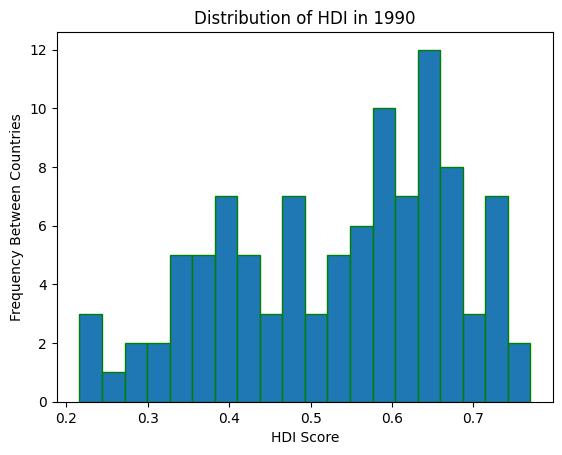

In [78]:
#I now want to see the distribution of HDI in just 1900 so I can compare how that has changed
#from then to 2021.
plt.hist(ninety["Human Development Index"], bins=20, edgecolor="green")
plt.title("Distribution of HDI in 1990")
plt.xlabel("HDI Score")
plt.ylabel("Frequency Between Countries")
plt.show()
#It looks like there is a medium frequency in the 0.4 range which is probably a lot of
#the underdeveloped countries. But the highest frequency in HDI is between 0.6 and 0.7.

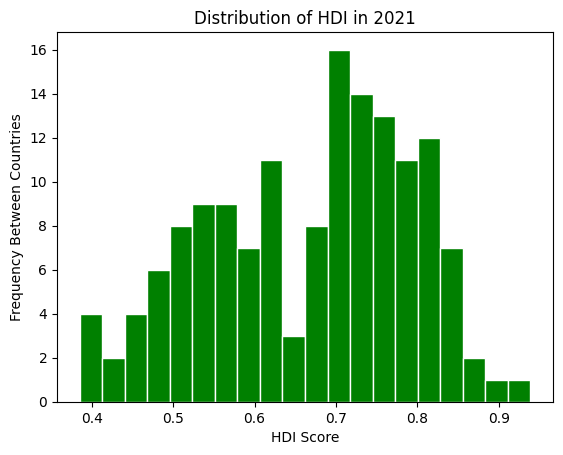

In [77]:
#I now want to see the distribution of HDI in just 2021 because that is the most relevant to now
#(since 2021 is the last year on the dataset.)
plt.hist(twentyone["Human Development Index"], bins=20, color="green", edgecolor = 'white')
plt.title("Distribution of HDI in 2021")
plt.xlabel("HDI Score")
plt.ylabel("Frequency Between Countries")
plt.show()
#it is quite interesting because luckily the highest frequency of HDI scores is in the 0.7 range which is relatively high.
#This is awesome to see because not only does it show that the highest frequencies have improved to 0.7, but there are higher scores
#than 1990. On the 1990 range, there were no countries that scored above 0.75 range. Now in 2021 there are countries
#that score in the 0.9 range!

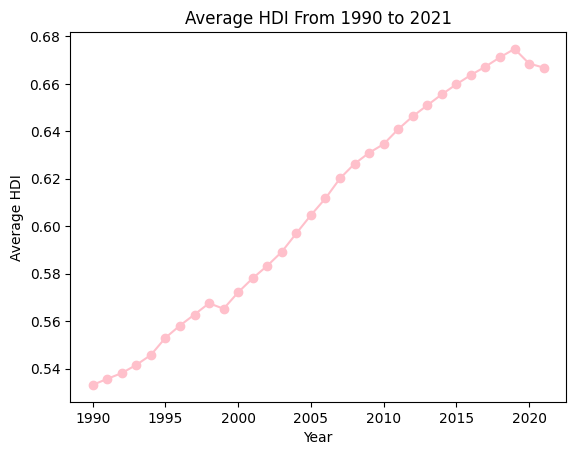

In [79]:
#also want to see how the average HDI changed over time
yearly = hd.groupby("Year")["Human Development Index"].mean()
plt.plot(yearly.index, yearly.values, marker="o", color = 'pink')
plt.title("Average HDI From 1990 to 2021")
plt.xlabel("Year")
plt.ylabel("Average HDI")
plt.show()
#This is awesome because it looks like over time, just like the histogram showed,
#average HDI has jumped from 0.54 to 0.67!

In [110]:
#want to see differences between 1990 and 2021 for which region had the highest and lowest HDI
category_groups90= ninety.groupby('Region')
summary_df90 = category_groups90.agg(
    lowest_hdi = ('Human Development Index', 'min'),
    highest_hdi = ('Human Development Index', 'max'),
    CHI_STD = ('Coefficient of human inequality', 'std'),
    average_hdi = ('Human Development Index', 'mean')
).reset_index()
print(summary_df90)
summary_df90.sort_values(by= 'lowest_hdi')
summary_df90.sort_values(by= 'highest_hdi', ascending = False)
#in 1990, it looks like Africa had the lowest HDI with 0.216
#and Southeast Asia had the highest HDI with an average score of 0.770

             Region  lowest_hdi  highest_hdi  CHI_STD  average_hdi
0            Africa       0.216        0.666      NaN     0.436676
1         Caribbean       0.429        0.725      NaN     0.631429
2   Central America       0.484        0.669      NaN     0.562429
3      Central Asia       0.628        0.673      NaN     0.646333
4         East Asia       0.484        0.579      NaN     0.531500
5            Europe       0.647        0.729      NaN     0.671250
6     North America       0.662        0.662      NaN     0.662000
7           Oceania       0.370        0.645      NaN     0.554000
8     South America       0.509        0.723      NaN     0.630455
9        South Asia       0.273        0.636      NaN     0.423167
10   Southeast Asia       0.333        0.770      NaN     0.543500
11  The Middle East       0.383        0.758      NaN     0.629091


,Region,lowest_hdi,highest_hdi,CHI_STD,average_hdi
10,Southeast Asia,0.333,0.770,NaN,0.543500
11,The Middle East,0.383,0.758,NaN,0.629091
5,Europe,0.647,0.729,NaN,0.671250
1,Caribbean,0.429,0.725,NaN,0.631429
8,South America,0.509,0.723,NaN,0.630455
3,Central Asia,0.628,0.673,NaN,0.646333
2,Central America,0.484,0.669,NaN,0.562429
0,Africa,0.216,0.666,NaN,0.436676
6,North America,0.662,0.662,NaN,0.662000
7,Oceania,0.370,0.645,NaN,0.554000


In [113]:
#I want to see differences between 1990 and 2021 for which region had the highest and lowest HDI
category_groups= twentyone.groupby('Region')
summary_df = category_groups.agg(
    lowest_hdi = ('Human Development Index', 'min'),
    highest_hdi = ('Human Development Index', 'max'),
    CHI_STD = ('Coefficient of human inequality', 'std'),
    average_hdi = ('Human Development Index', 'mean')
).reset_index()
summary_df.sort_values(by= 'lowest_hdi')
summary_df.sort_values(by= 'highest_hdi', ascending = False)
#in 2021, it looks like Africa had the lowest HDI with 0.385
#and Southeast Asia had the highest HDI with an average score of 0.939
#this is awesome because both have improved for both countries, but I do want to
#see what are the top 5 countries in Southeast Asia for HDI

,Region,lowest_hdi,highest_hdi,CHI_STD,average_hdi
10,Southeast Asia,0.585,0.939,4.898408,0.715455
11,The Middle East,0.455,0.911,6.845859,0.759571
8,South America,0.691,0.855,3.901169,0.754833
5,Europe,0.745,0.832,2.355723,0.784909
1,Caribbean,0.535,0.812,9.296539,0.748692
3,Central Asia,0.685,0.811,4.091368,0.732000
2,Central America,0.621,0.809,2.973693,0.698143
0,Africa,0.385,0.802,5.947025,0.558981
9,South Asia,0.478,0.782,5.341225,0.639125
4,East Asia,0.739,0.768,1.451473,0.753500


In [116]:
#Since southeast Asia was so good for HDI, I want to see a couple other things with them!
#I also just want to look for Southeast Asia in 2021
se_asia = twentyone[twentyone['Region'] == 'Southeast Asia']
#just checking out some interesting stuff
#it looks like Brunei had the highest HDI in this region, but I want to see more
category_asia= se_asia.groupby('Country')
summary_se = category_asia.agg(
    avg_hdi = ('Human Development Index', 'mean'),
    gross_income_mean = ('Gross National Income Per Capita', 'mean'),
    life_expect_avg = ('Life Expectancy at Birth', 'mean'),
    gender_ineqal_avg = ('Gender Inequality Index', 'mean'),
    years_school_avg = ('Mean Years of Schooling', 'mean')
).reset_index()
print(summary_se)

#this is super interesting! The top 5 countries all have different gross income per capita,
#but that is cool that it doesnt mean everything.

        Country  avg_hdi  gross_income_mean  life_expect_avg  \
0        Brunei    0.829       64489.539540          74.6424   
1      Cambodia    0.593        4078.697154          69.5835   
2     Indonesia    0.705       11466.068360          67.5703   
3           Lao    0.607        7699.579617          68.0608   
4      Malaysia    0.803       26657.943550          74.8839   
5       Myanmar    0.585        3850.524234          65.6716   
6   Philippines    0.699        8920.428468          69.2664   
7     Singapore    0.939       90918.644710          82.7545   
8      Thailand    0.800       17030.153520          78.7154   
9   Timor-Leste    0.607        4460.869435          67.7369   
10     Viet Nam    0.703        7867.371345          73.6181   

    gender_ineqal_avg  years_school_avg  
0               0.259           9.18000  
1               0.461           5.08800  
2               0.444           8.55651  
3               0.478           5.37400  
4               0.228

# **2. Life expectancy and health**

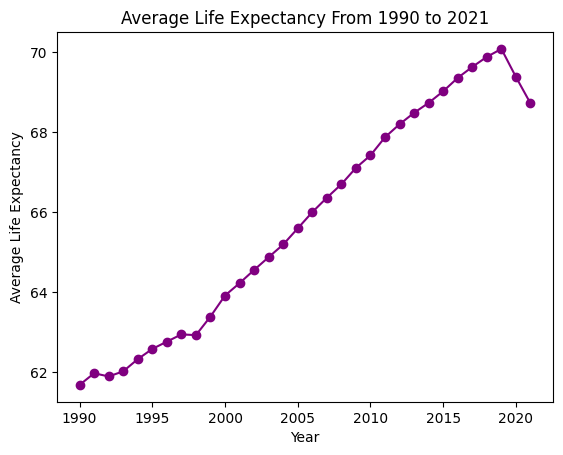

In [82]:
#I want to see the life expectancy over time
yearly = hd.groupby("Year")["Life Expectancy at Birth"].mean()
plt.plot(yearly.index, yearly.values, marker="o", color = 'purple')
plt.title("Average Life Expectancy From 1990 to 2021")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy")
plt.show()
#This is also good because life expectancy has been a steady increase since
#1990 from 62 years to around 70. I did notice on this graph and an earlier one
#that there was a decrease after 2020, and this is probaby because of covid. I will also
#look at a graph from 2019 to 2021.

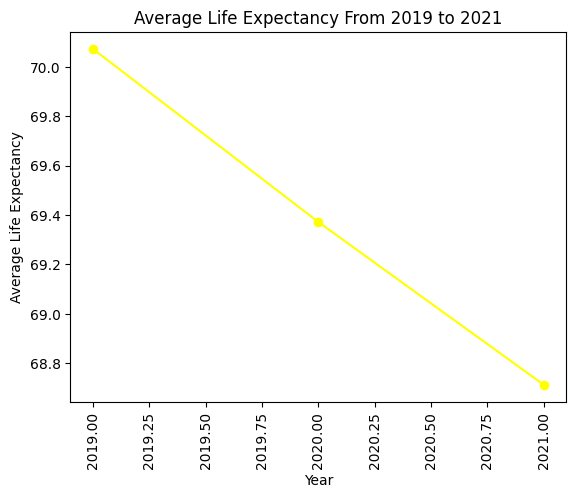

In [123]:
#Just curious about covid, so I will look at average life expectancy from 2019 to 2021.
#I will also look at mortality rate after
covid = hd[(hd['Year'] >= 2019) & (hd['Year'] <= 2021)]
yearly_covid = covid.groupby("Year")["Life Expectancy at Birth"].mean()
plt.plot(yearly_covid.index, yearly_covid.values, marker="o", color = 'yellow')
plt.title("Average Life Expectancy From 2019 to 2021")
plt.xlabel("Year")
plt.ylabel("Average Life Expectancy")
plt.xticks(rotation = 90)
plt.show()
#interesting, the life expectancy went from 70 to 68.8 in those two years.
# i also am curious so I want to see overall loss.

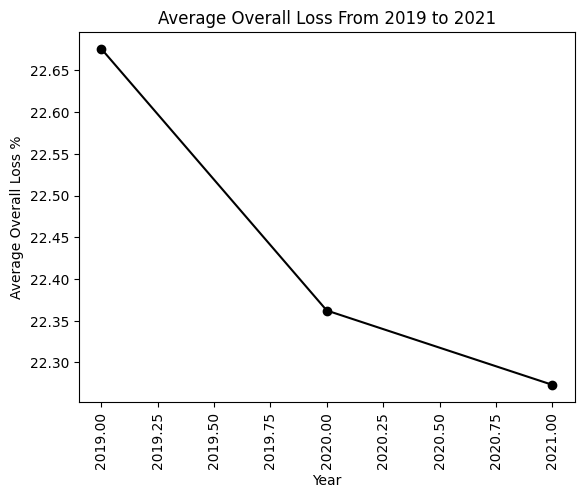

In [126]:
#overall loss for covid is what I am looking at.
yearly_loss = covid.groupby("Year")["Overall loss (%)"].mean()
plt.plot(yearly_loss.index, yearly_loss.values, marker="o", color = 'black')
plt.title("Average Overall Loss From 2019 to 2021")
plt.xlabel("Year")
plt.ylabel("Average Overall Loss %")
plt.xticks(rotation = 90)
plt.show()
#this is also interesting because the overall loss percentage from 2019 to 2021.

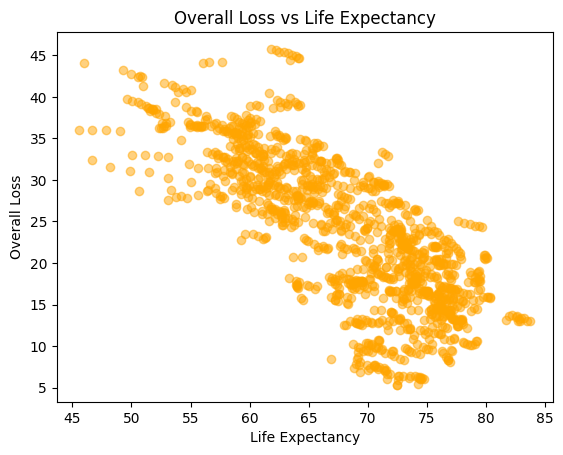

-0.7668486497634581


np.float64(-0.7668486497634581)

In [129]:
#i want to see the relation between average life expectancy and overall loss
from scipy.stats import pearsonr
r, p = pearsonr(hd['Overall loss (%)'],
                hd['Life Expectancy at Birth'])
plt.scatter(hd["Life Expectancy at Birth"], hd["Overall loss (%)"], alpha=0.5, color = 'orange')
plt.title("Overall Loss vs Life Expectancy")
plt.xlabel("Life Expectancy")
plt.ylabel("Overall Loss")

plt.show()

r = hd['Life Expectancy at Birth'].corr(hd['Overall loss (%)'])

print(r)
hd['Overall loss (%)'].corr(
    hd['Life Expectancy at Birth']
)
#this is very interesting because the correlation is medium. It is -0.77
#which is pretty close to -1. So a medium negative correlation.

# **3. Education and Schooling**

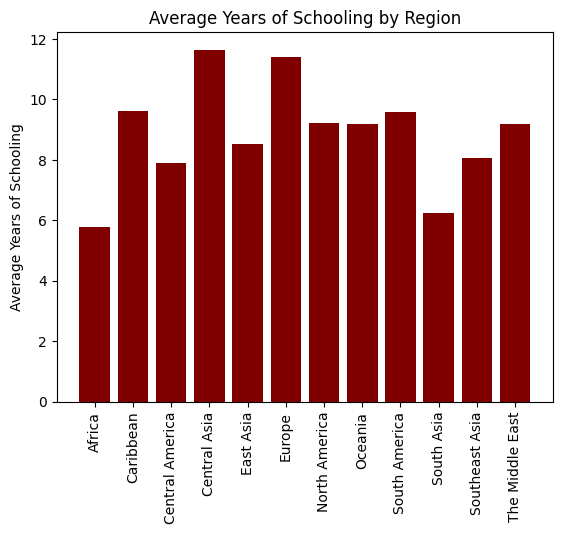

In [130]:
#I want to see the comparisons in mean years of schooling in 2021
#Mean Years of Schooling in 2021
means = twentyone.groupby("Region")["Mean Years of Schooling"].mean()
plt.bar(means.index, means.values, color = 'maroon')
plt.title("Average Years of Schooling by Region")
plt.ylabel("Average Years of Schooling")
plt.xticks(rotation=90)
plt.show()
#Ok. The highest average years of schooling are the Central Asia and Europe
#regions. That is interesting because schooling is probably more affordable
#because in underdeveloped regions people get little schooling.
#for example, africa has the lowest average with it being less than 6.

In [85]:
#now I am curious which country specifically had the lowest and highest amount of years of schooling
#in 2021
twentyone.loc[twentyone['Mean Years of Schooling'].idxmin()]
#lowest was Burkina Faso with the minimum being 9.14.
#this checks cause the bar charts lowest was africa and africa is the region
# of Burkina Faso

,351
ISO3,BFA
Country,Burkina Faso
Human Development Groups,Low
UNDP Developing Regions,SSA
HDI Rank (2021),184.0
Year,2021
"Adolescent Birth Rate (births per 1,000 women ages 15-19)",110.509
Carbon dioxide emissions per capita (production) (tonnes),0.189903
Coefficient of human inequality,29.275306
Difference from HDI rank,1.0


In [86]:
#now checking the highest
twentyone.loc[twentyone['Mean Years of Schooling'].idxmax()]
#highest was georgia with the expected years of schooling being 15.57
#also checks since Europe was one of the highest and Georgia
#is in Europe

,1503
ISO3,GEO
Country,Georgia
Human Development Groups,Very High
UNDP Developing Regions,ECA
HDI Rank (2021),63.0
Year,2021
"Adolescent Birth Rate (births per 1,000 women ages 15-19)",31.654
Carbon dioxide emissions per capita (production) (tonnes),2.498792
Coefficient of human inequality,11.411614
Difference from HDI rank,34.0


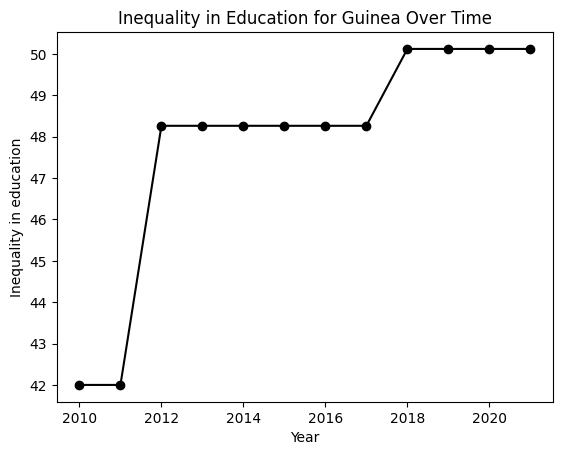

In [103]:
#similarly want to see the worst country for Inequality in Education Index
#so the bigger the number the bigger the index, which means higher inequality
#when its comes to inequality in education and see how that average number has increased over time

hd.loc[hd['Inequality in education'].idxmax()]
#it is Guniea with number being the highest at 50.1
guinea = hd[hd['Country'] == 'Guinea']

# Calculate average inequality in education for each year
yearly = guinea.groupby('Year')['Inequality in education'].mean()

# Create line chart
plt.plot(yearly.index, yearly.values, marker='o', color='black')
plt.title("Inequality in Education for Guinea Over Time")
plt.xlabel("Year")
plt.ylabel("Inequality in education")
plt.show()
#this is interesting because more countries typically go down over time
#with improvements. But Guniea actually went up in the inequality. They had
#not as bad inequality in 2010, but 2021 it was at its peak. It
#may because of the government there that may have changed.


# **4. Gender inequality**

In [92]:
#I want to make a bar chart comparing the male vs female labor force participation by region.
twentyone_copy = twentyone.copy()
labor_force = twentyone.melt(
    id_vars='Region',
    value_vars=[
        'Labour force participation rate, female (% ages 15 and older)',
        'Labour force participation rate, male (% ages 15 and older)'
    ],
    var_name='Gender',
    value_name='Labor Force Participation'
)

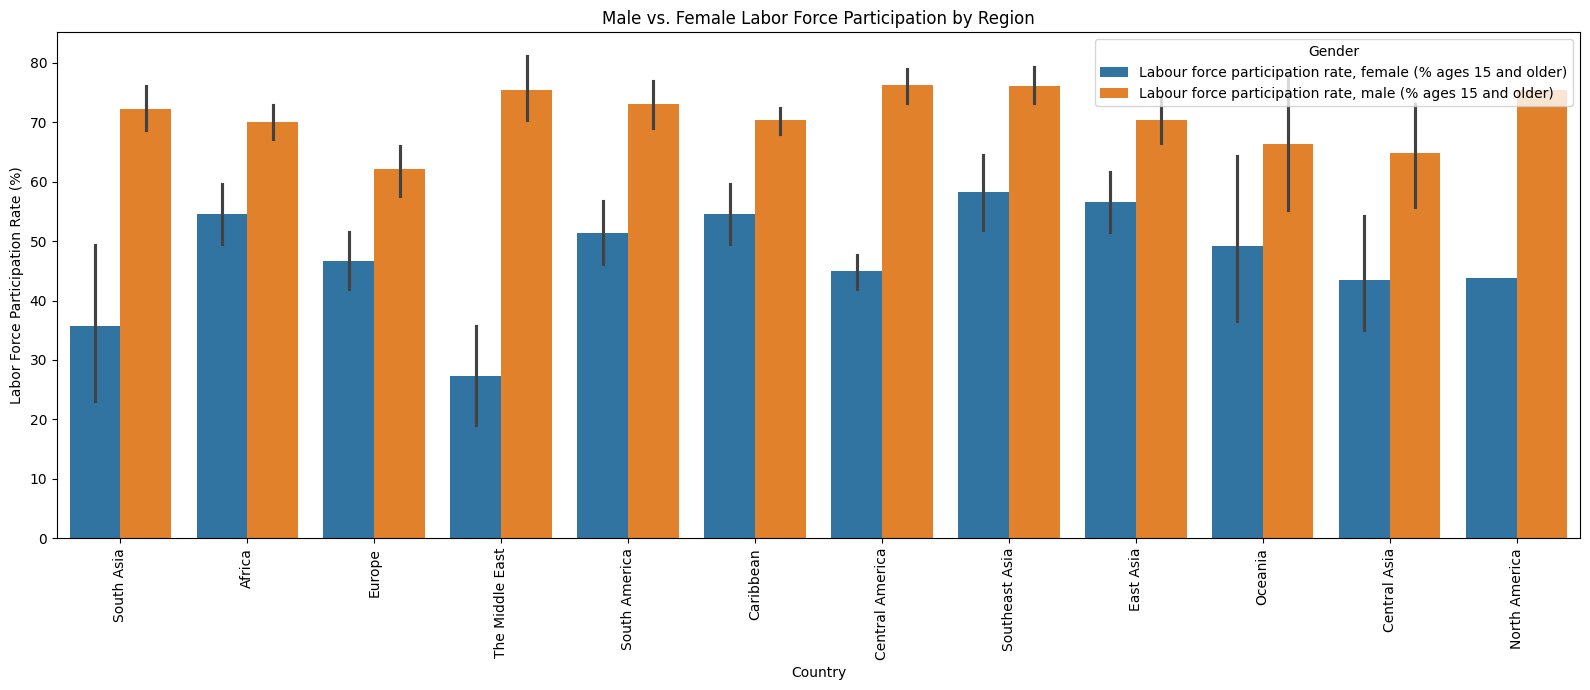

In [131]:
plt.figure(figsize=(16, 7))

sns.barplot(
    data=labor_force,
    x='Region',
    y='Labor Force Participation',
    hue='Gender'
)

plt.xticks(rotation=90)
plt.title('Male vs. Female Labor Force Participation by Region')
plt.ylabel('Labor Force Participation Rate (%)')
plt.xlabel('Country')
plt.legend(title='Gender')
plt.tight_layout()
plt.show()
#the biggest differences between gender is in South Asia and The Middle East. This
#may be because of relgious beliefs where woman are not supposed to work (such as Islam)

In [93]:
#want to see how gender inequality has improved over time
hd_gender= hd.groupby('Year')
summary_gender = hd_gender.agg(
    gender_inequality_average = ('Gender Inequality Index', 'mean')
).reset_index()
print(summary_gender)

    Year  gender_inequality_average
0   1990                   0.590663
1   1991                   0.587854
2   1992                   0.585315
3   1993                   0.583270
4   1994                   0.580135
5   1995                   0.574901
6   1996                   0.570440
7   1997                   0.565747
8   1998                   0.559268
9   1999                   0.551775
10  2000                   0.542857
11  2001                   0.536145
12  2002                   0.529568
13  2003                   0.522325
14  2004                   0.515957
15  2005                   0.507558
16  2006                   0.495024
17  2007                   0.484226
18  2008                   0.481427
19  2009                   0.477879
20  2010                   0.476452
21  2011                   0.471039
22  2012                   0.464367
23  2013                   0.456539
24  2014                   0.454164
25  2015                   0.447930
26  2016                   0

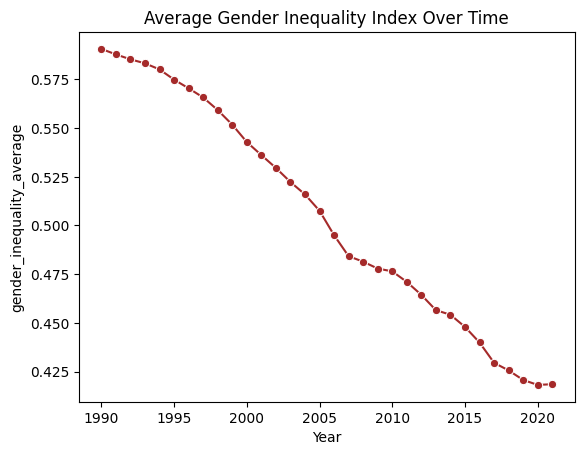

In [94]:
sns.lineplot(data=summary_gender, x="Year", y="gender_inequality_average", errorbar=None, marker="o", color = 'brown')
plt.title('Average Gender Inequality Index Over Time')
plt.show()
#just as I explained earlier, the inequality index gets worse as it goes up.
# this is really great because over all the gender inequality index has slowly gone down
#since 1990.

# **5. Environmental impact and sustainable development**

In [133]:
# I want to see what country had the worst carbon dioxide emissions per capita.
#in 2021
emissions= twentyone.groupby('Country')
summary_CO = emissions.agg(
   CO2_average = ('Carbon dioxide emissions per capita (production) (tonnes)', 'mean')
).reset_index()
summary_CO.sort_values(by= 'CO2_average', ascending = False)
#quatar had the worst emissions per capita being 37.01. Then Mongolia

,Country,CO2_average
105,Qatar,37.019451
85,Mongolia,26.978028
132,Trinidad and Tobago,25.373136
20,Brunei,23.220543
67,Kuwait,20.825107
...,...,...
93,Niger,0.069832
27,Chad,0.055540
22,Burundi,0.050643
26,Central African Republic,0.038907


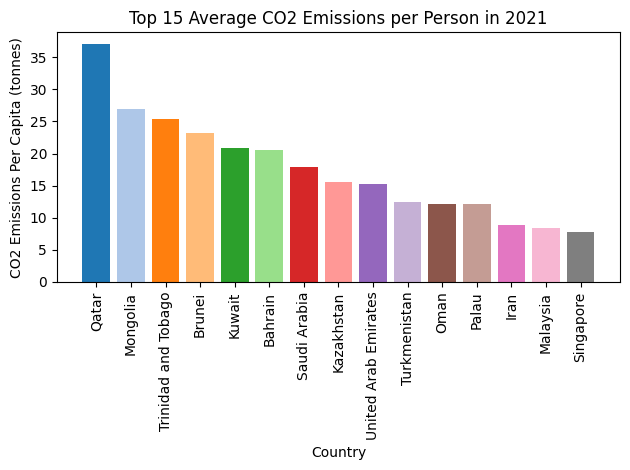

In [96]:
#want to make a chart top countries of the carbon dioxide
#emissions within the regions

means = twentyone.groupby("Country")[
    "Carbon dioxide emissions per capita (production) (tonnes)"
].mean()

top15 = means.nlargest(15)

plt.bar(top15.index, top15.values)
plt.title("Top 15 Average CO2 Emissions per Person in 2021")
plt.ylabel("CO2 Emissions Per Capita (tonnes)")
plt.xlabel("Country")
plt.xticks(rotation=90)
plt.tight_layout()
plt.bar(top15.index, top15.values, color=plt.cm.tab20.colors[:15])
plt.show()

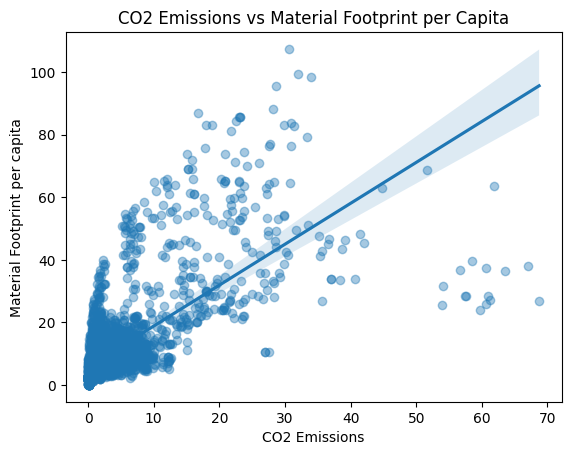

0.6939875590021317


np.float64(0.6939875590021317)

In [135]:
# also want to see the realtion between Co2 emissions and
#Material footprint per capita (tonnes)'
r, p = pearsonr(hd['Carbon dioxide emissions per capita (production) (tonnes)'],
                hd['Material footprint per capita (tonnes)'])

plt.show()
sns.regplot(data=hd, x="Carbon dioxide emissions per capita (production) (tonnes)",
            y="Material footprint per capita (tonnes)", scatter_kws={"alpha":0.4})
plt.title("CO2 Emissions vs Material Footprint per Capita")
plt.xlabel("CO2 Emissions")
plt.ylabel("Material Footprint per capita")
plt.show()

r = hd['Carbon dioxide emissions per capita (production) (tonnes)'].corr(hd['Material footprint per capita (tonnes)'])

print(r)
hd['Carbon dioxide emissions per capita (production) (tonnes)'].corr(
    hd['Material footprint per capita (tonnes)']
)
#a medium correlation. The r value is 0.69, so relatively close to 1.
#This would be a medium positive correlation.